In [1]:
%pip install numpy==1.26.4 --force-reinstall --no-cache-dir


%pip install pandas networkx matplotlib scikit-learn gensim openpyxl tqdm --quiet

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 14.0 MB 12.0 MB/s eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import networkx as nx
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import torch.nn as nn
import torch.optim as optim
from collections import defaultdict

In [3]:
# Load the data
df = pd.read_excel("Payments.xlsx")
df.columns = ['source', 'target', 'amount']

torch.cuda.is_available()

In [4]:
torch.cuda.is_available()

False

In [5]:
class Node2VecTorch:
    def __init__(self, graph, dimensions=64, walk_length=10, num_walks=100, window_size=5, num_negative=5, batch_size=1024):
        self.graph = graph
        self.walk_length = walk_length
        self.num_walks = num_walks
        self.window_size = window_size
        self.dimensions = dimensions
        self.num_negative = num_negative
        self.batch_size = batch_size

        self.nodes = list(graph.nodes())
        self.node2idx = {node: i for i, node in enumerate(self.nodes)}
        self.idx2node = {i: node for node, i in self.node2idx.items()}

    def generate_walks(self):
        walks = []
        for _ in range(self.num_walks):
            random.shuffle(self.nodes)
            for node in self.nodes:
                walk = self.random_walk(node)
                walks.append(walk)
        return walks

    def random_walk(self, start):
        walk = [start]
        while len(walk) < self.walk_length:
            cur = walk[-1]
            neighbors = list(self.graph.successors(cur))
            if not neighbors:
                break
            walk.append(random.choice(neighbors))
        return walk

    def generate_skipgram_pairs(self, walks):
        pairs = []
        for walk in walks:
            for i, center in enumerate(walk):
                actual_window = random.randint(1, self.window_size)
                window = walk[max(i - actual_window, 0): i + actual_window + 1]
                for context in window:
                    if context != center:
                        pairs.append((self.node2idx[center], self.node2idx[context]))
        return pairs

    def train(self, pairs, epochs=5, lr=0.01):
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        num_nodes = len(self.nodes)
        embed_in = nn.Embedding(num_nodes, self.dimensions).to(device)
        embed_out = nn.Embedding(num_nodes, self.dimensions).to(device)

        optimizer = optim.Adam(list(embed_in.parameters()) + list(embed_out.parameters()), lr=lr)
        loss_fn = nn.BCEWithLogitsLoss(reduction='mean')

        pairs = np.array(pairs)

        for epoch in range(epochs):
            np.random.shuffle(pairs)
            total_loss = 0
            total_samples = 0

            for i in tqdm(range(0, len(pairs), self.batch_size), desc=f"Epoch {epoch+1}"):
                batch = pairs[i:i+self.batch_size]
                center_batch = torch.tensor(batch[:, 0], dtype=torch.long, device=device)
                context_batch = torch.tensor(batch[:, 1], dtype=torch.long, device=device)

                center_embeds = embed_in(center_batch)
                context_embeds = embed_out(context_batch)

                pos_scores = torch.sum(center_embeds * context_embeds, dim=1)
                pos_labels = torch.ones(pos_scores.size(), device=device)
                loss = loss_fn(pos_scores, pos_labels)

                # Negative sampling using uniform distribution
                negative_samples = torch.randint(0, num_nodes, (self.num_negative * center_batch.size(0),), device=device)
                neg_contexts = embed_out(negative_samples)
                repeated_centers = center_embeds.repeat_interleave(self.num_negative, dim=0)

                neg_scores = torch.sum(repeated_centers * neg_contexts, dim=1)
                neg_labels = torch.zeros(neg_scores.size(), device=device)
                loss += loss_fn(neg_scores, neg_labels)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * center_batch.size(0)
                total_samples += center_batch.size(0)

            avg_loss = total_loss / total_samples
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

        # Normalize embeddings
        final_embeds = embed_in.weight.detach().cpu()
        norms = torch.norm(final_embeds, dim=1, keepdim=True)
        return (final_embeds / norms).numpy()


In [6]:

# Step 1: Create a MultiDiGraph
multi_graph = nx.MultiDiGraph()
for _, row in df.iterrows():
    multi_graph.add_edge(row['source'], row['target'], weight=row['amount'])

In [7]:

# Step 2: Convert to a simple DiGraph with aggregated edge weights
graph = nx.DiGraph()
for u, v, data in multi_graph.edges(data=True):
    if graph.has_edge(u, v):
        graph[u][v]['weight'] += data['weight']
    else:
        graph.add_edge(u, v, weight=data['weight'])

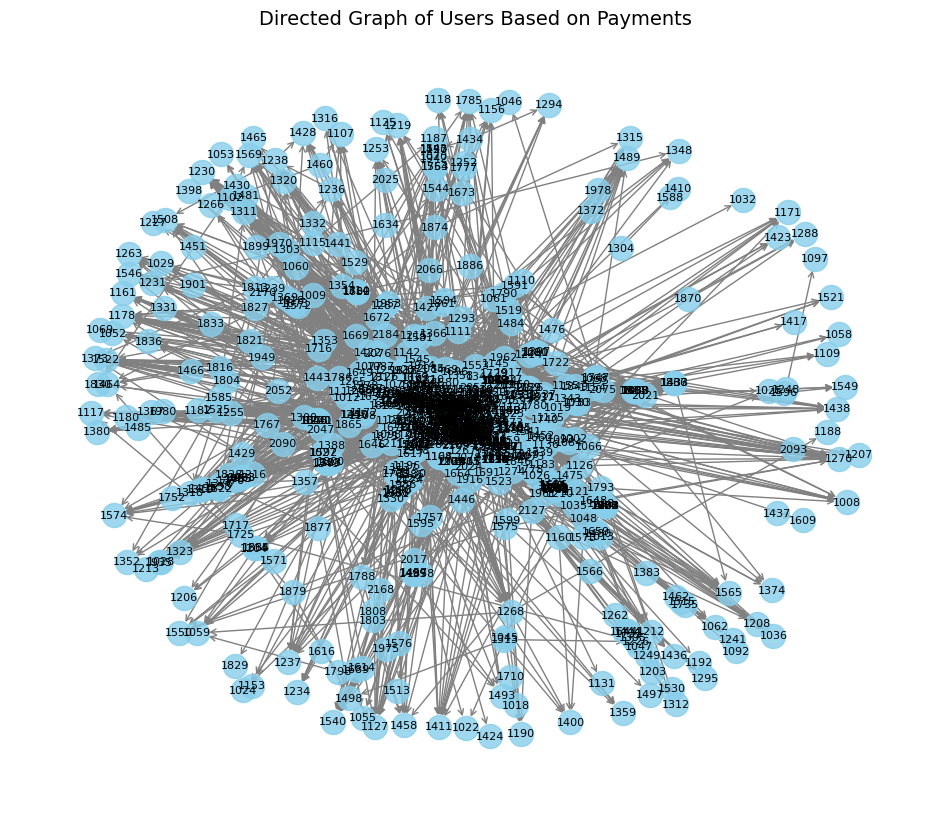

In [8]:

# Step 3: Visualize the directed graph
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(graph, seed=42)
weights = [graph[u][v]['weight'] for u, v in graph.edges()]
nx.draw_networkx_nodes(graph, pos, node_size=300, node_color='skyblue', alpha=0.8)
nx.draw_networkx_edges(graph, pos, edgelist=graph.edges(), arrowstyle='->', arrowsize=10,
                       edge_color='gray', width=1)
nx.draw_networkx_labels(graph, pos, font_size=8)
plt.title("Directed Graph of Users Based on Payments", fontsize=14)
plt.axis('off')
plt.show()

In [9]:
from tqdm import tqdm
# Step 5: Train node2vec and get embeddings

n2v = Node2VecTorch(graph)
walks = n2v.generate_walks()
pairs = n2v.generate_skipgram_pairs(walks)
embeddings = n2v.train(pairs, epochs=20)

Epoch 1: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 1864/1864 [00:02<00:00, 910.99it/s]


Epoch 1, Loss: 0.9836


Epoch 2: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 1864/1864 [00:02<00:00, 879.06it/s]


Epoch 2, Loss: 0.5547


Epoch 3: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████| 1864/1864 [00:02<00:00, 896.15it/s]


...

Epoch 18, Loss: 0.5283


Epoch 19: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 1864/1864 [00:02<00:00, 736.39it/s]


Epoch 19, Loss: 0.5283


Epoch 20: 100%|████████████████████████████████████████████████████████████████████████████████████████████████| 1864/1864 [00:02<00:00, 817.13it/s]

Epoch 20, Loss: 0.5279


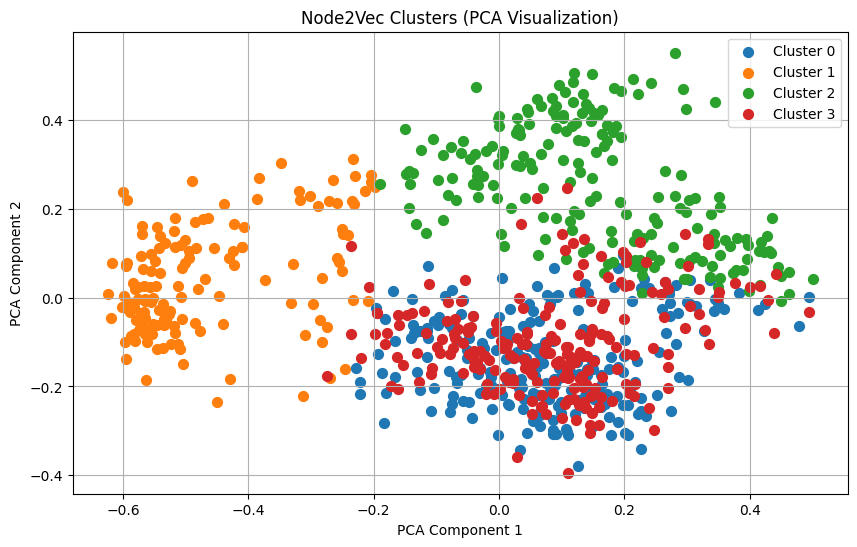

In [10]:
# Step 6: Apply clustering
kmeans = KMeans(n_clusters=4, random_state=42)
clusters = kmeans.fit_predict(embeddings)

# Step 7: Reduce dimensions for visualization
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

# Step 8: Visualize clusters using PCA with legends
plt.figure(figsize=(10, 6))
for cluster_id in range(4):
    plt.scatter(
        reduced_embeddings[clusters == cluster_id, 0],
        reduced_embeddings[clusters == cluster_id, 1],
        label=f'Cluster {cluster_id}',
        s=50
    )

plt.title("Node2Vec Clusters (PCA Visualization)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.grid(True)
plt.show()